In [1]:
# ============================================================
# Cell 1: Project setup
# ============================================================

# Assignment coverage:
# 1. OPSD German hourly electricity load data
# 2. Daily and weekly aggregation
# 3. EDA and stationarity analysis
# 4. Benchmark models: mean, naive, seasonal naive and drift
# 5. SARIMA with AIC parameter search over p=0..6, d=0..2, q=0..6
# 6. SARIMA residual diagnostics and confidence intervals
# 7. SARIMAX with Berlin temperature as an exogenous variable
# 8. Feature-based regression model
# 9. LSTM model using hourly data
# 10. Final comparison against seasonal naive benchmark

import warnings
warnings.filterwarnings("ignore")

print("Notebook objective:")
print("Forecast German electricity load and test whether advanced models beat seasonal naive forecasting.")

Notebook objective:
Forecast German electricity load and test whether advanced models beat seasonal naive forecasting.


In [2]:
# ============================================================
# Cell 2: Imports, plotting settings and evaluation functions
# ============================================================

import os
import itertools
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from math import sqrt
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.preprocessing import MinMaxScaler

from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["font.size"] = 10

FIG_DIR = "figures"
OUT_DIR = "outputs"

os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

def rmse(y_true, y_pred):
    """Calculate Root Mean Squared Error."""
    return sqrt(mean_squared_error(y_true, y_pred))

def smape(y_true, y_pred):
    """Calculate Symmetric Mean Absolute Percentage Error."""
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    denominator = (np.abs(y_true) + np.abs(y_pred)) / 2
    denominator = np.where(denominator == 0, 1, denominator)
    return np.mean(np.abs(y_true - y_pred) / denominator) * 100

def evaluate_forecast(model_name, y_true, y_pred, seasonal_naive_rmse=None):
    """Return a dictionary of evaluation metrics for a forecast."""
    model_rmse = rmse(y_true, y_pred)
    model_mae = mean_absolute_error(y_true, y_pred)
    model_smape = smape(y_true, y_pred)

    if seasonal_naive_rmse is None:
        improvement = np.nan
    else:
        improvement = ((seasonal_naive_rmse - model_rmse) / seasonal_naive_rmse) * 100

    return {
        "Model": model_name,
        "RMSE": model_rmse,
        "MAE": model_mae,
        "sMAPE": model_smape,
        "Improvement_vs_Seasonal_Naive_%": improvement
    }

def save_figure(filename):
    """Save current matplotlib figure with good resolution."""
    path = os.path.join(FIG_DIR, filename)
    plt.tight_layout()
    plt.savefig(path, dpi=300, bbox_inches="tight")
    print(f"Saved figure: {path}")

metrics_results = []

print("Libraries imported and helper functions created.")

Libraries imported and helper functions created.


In [4]:
# ============================================================
# Cell 3: Load dataset and select German electricity load
# ============================================================

DATA_PATH = "time_series_60min_singleindex.csv"

target_col = "DE_load_actual_entsoe_transparency"
timestamp_col = "utc_timestamp"

# Read only the required timestamp and German load column to keep code fast.
df_raw = pd.read_csv(
    DATA_PATH,
    usecols=[timestamp_col, target_col],
    parse_dates=[timestamp_col]
)

df_raw = df_raw.rename(columns={target_col: "load"})
df_raw = df_raw.set_index(timestamp_col).sort_index()

# Keep data from 1 January 2015 until the end of the file, as required.
df_hourly = df_raw.loc["2015-01-01":].copy()

# Check data quality.
print("Dataset check")
print("-" * 60)
print(f"Rows after filtering from 2015-01-01: {df_hourly.shape[0]}")
print(f"Columns: {df_hourly.shape[1]}")
print(f"Start timestamp: {df_hourly.index.min()}")
print(f"End timestamp: {df_hourly.index.max()}")
print(f"Missing load values: {df_hourly['load'].isna().sum()}")
print()
print("Load summary statistics")
print(df_hourly["load"].describe())

# Fill missing values only if any exist.
# The uploaded file normally has no missing German load values after 2015-01-01.
df_hourly["load"] = df_hourly["load"].interpolate(method="time")

print("\nFinal missing values after interpolation:", df_hourly["load"].isna().sum())

Dataset check
------------------------------------------------------------
Rows after filtering from 2015-01-01: 50400
Columns: 1
Start timestamp: 2015-01-01 00:00:00+00:00
End timestamp: 2020-09-30 23:00:00+00:00
Missing load values: 0

Load summary statistics
count    50400.000000
mean     55492.468552
std      10015.431042
min      31307.000000
25%      47106.000000
50%      55092.000000
75%      64309.250000
max      77549.000000
Name: load, dtype: float64

Final missing values after interpolation: 0


Aggregated data summary
------------------------------------------------------------
Hourly observations: 50400
Daily observations: 2100
Weekly observations: 301
Weekly start date: 2015-01-04 00:00:00+00:00
Weekly end date: 2020-10-04 00:00:00+00:00
Saved figure: figures/figure_1_weekly_load_train_test.png


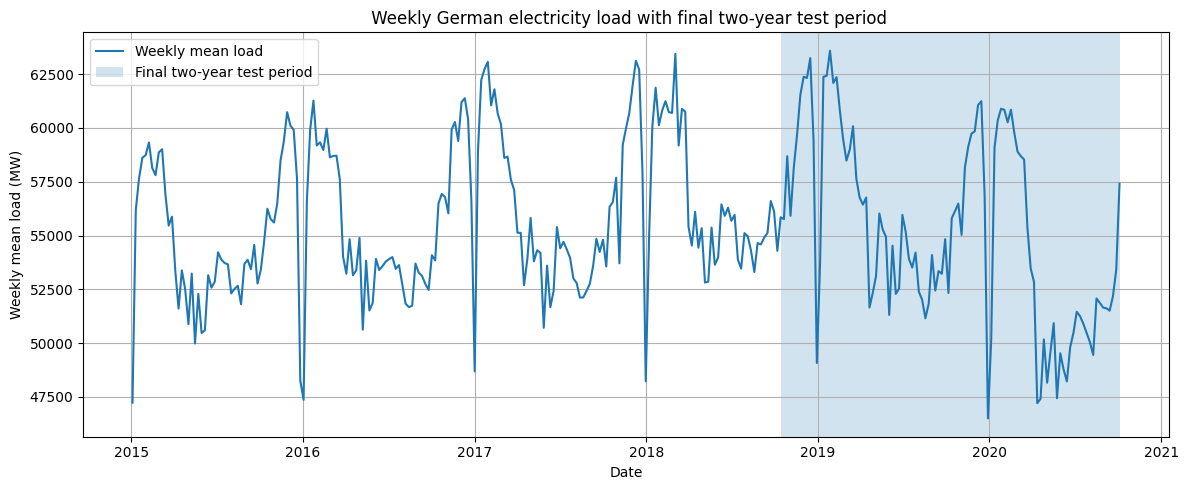

In [7]:
# ============================================================
# Cell 4: Create daily and weekly load data
# ============================================================
# The assignment requires binning the hourly data into daily and weekly values.
# Weekly mean load is used for the main benchmark, SARIMA, SARIMAX and ML models.
# Hourly load is retained for the LSTM model.

hourly_load = df_hourly["load"].copy()
daily_load = hourly_load.resample("D").mean()
weekly_load = hourly_load.resample("W-SUN").mean()

print("Aggregated data summary")
print("-" * 60)
print(f"Hourly observations: {len(hourly_load)}")
print(f"Daily observations: {len(daily_load)}")
print(f"Weekly observations: {len(weekly_load)}")
print(f"Weekly start date: {weekly_load.index.min()}")
print(f"Weekly end date: {weekly_load.index.max()}")

# Two-year forecast horizon = final 104 weeks.
test_size = 104
train_weekly = weekly_load.iloc[:-test_size]
test_weekly = weekly_load.iloc[-test_size:]

plt.figure(figsize=(12, 5))
plt.plot(weekly_load.index, weekly_load.values, label="Weekly mean load")
plt.axvspan(test_weekly.index[0], test_weekly.index[-1], alpha=0.2, label="Final two-year test period")
plt.title(" Weekly German electricity load with final two-year test period")
plt.xlabel("Date")
plt.ylabel("Weekly mean load (MW)")
plt.legend()
save_figure("figure_1_weekly_load_train_test.png")
plt.show()

Saved figure: figures/figure_2_weekly_seasonal_profile.png


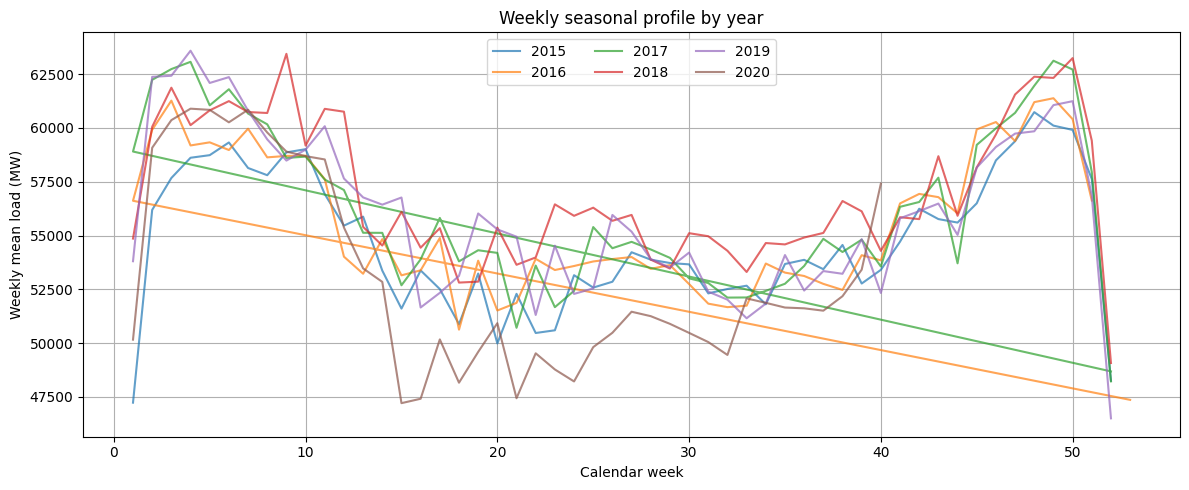

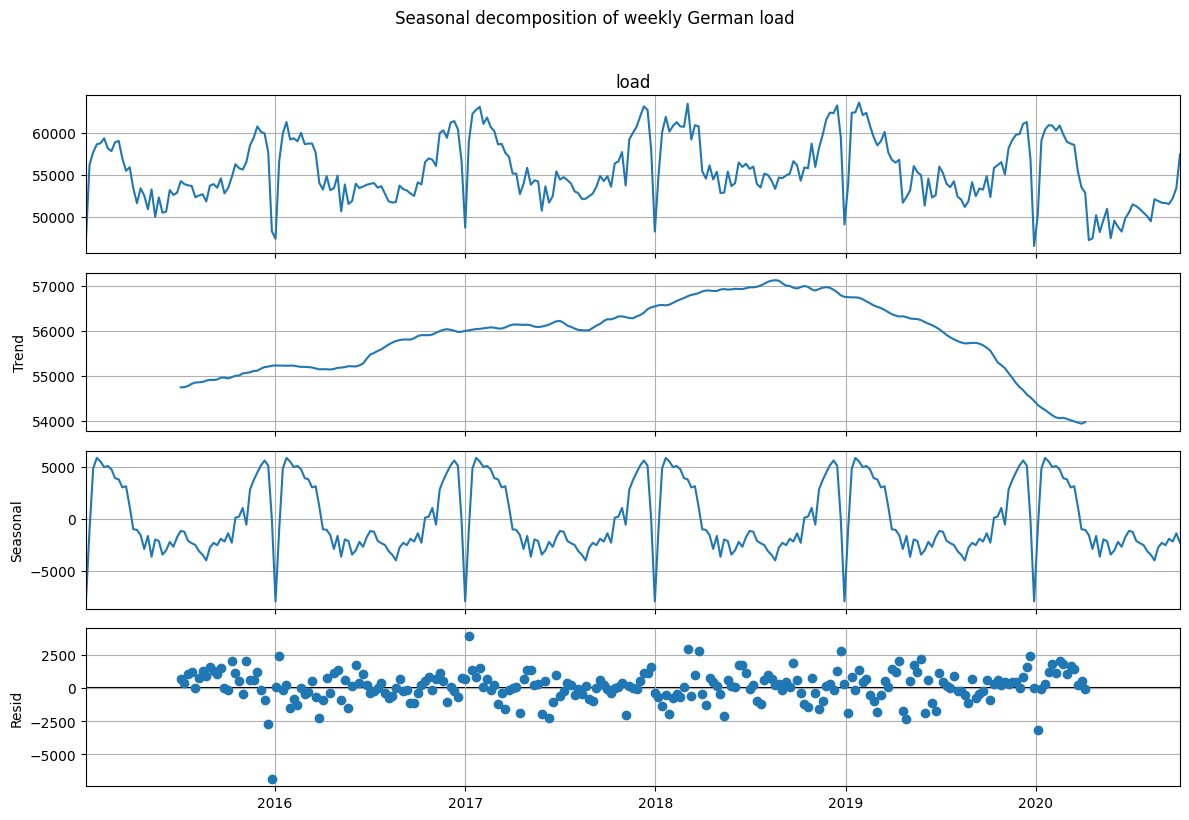

EDA interpretation note:
The seasonal profile and decomposition help justify using a 52-week seasonal period.
They also explain why seasonal naive is a strong benchmark rather than a weak baseline.


In [8]:
# ============================================================
# Cell 5: EDA and seasonal components
# ============================================================
# This section checks whether German weekly electricity load has a seasonal component.
# The seasonal pattern is important because seasonal naive is the main benchmark.

eda_df = weekly_load.to_frame(name="load")
eda_df["year"] = eda_df.index.year
eda_df["week"] = eda_df.index.isocalendar().week.astype(int)

# Figure 2: weekly seasonal profile by calendar week.
plt.figure(figsize=(12, 5))
for year in sorted(eda_df["year"].unique()):
    year_data = eda_df[eda_df["year"] == year]
    plt.plot(year_data["week"], year_data["load"], alpha=0.7, label=str(year))
plt.title("Weekly seasonal profile by year")
plt.xlabel("Calendar week")
plt.ylabel("Weekly mean load (MW)")
plt.legend(ncol=3)
save_figure("figure_2_weekly_seasonal_profile.png")
plt.show()

# Figure 3: seasonal decomposition.
# Weekly data uses period=52 to represent annual seasonality.
decomp = seasonal_decompose(weekly_load, model="additive", period=52)

fig = decomp.plot()
fig.set_size_inches(12, 8)
fig.suptitle("Seasonal decomposition of weekly German load", y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "figure_3_seasonal_decomposition.png"), dpi=300, bbox_inches="tight")
plt.show()

print("EDA interpretation note:")
print("The seasonal profile and decomposition help justify using a 52-week seasonal period.")
print("They also explain why seasonal naive is a strong benchmark rather than a weak baseline.")

Saved figure: figures/rolling_mean_std_weekly_load.png


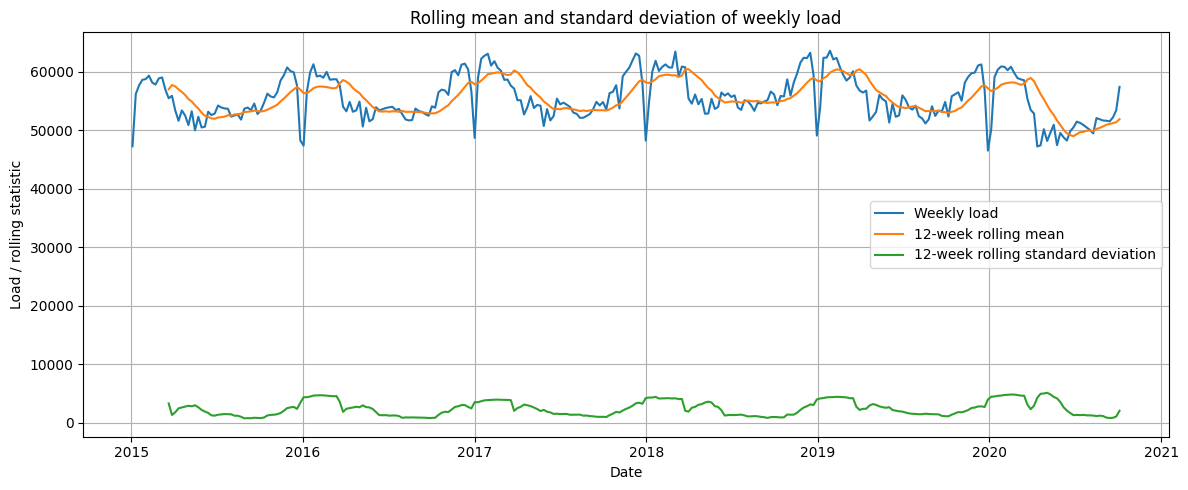

ADF test results


,Series,ADF Statistic,p-value,Lags Used,Observations,Conclusion
0,Original weekly load,-4.047472,1.181350e-03,8,292,Stationary
1,First differenced weekly load,-7.069318,4.984737e-10,7,292,Stationary
2,Seasonally differenced weekly load,-4.295072,4.530219e-04,2,246,Stationary


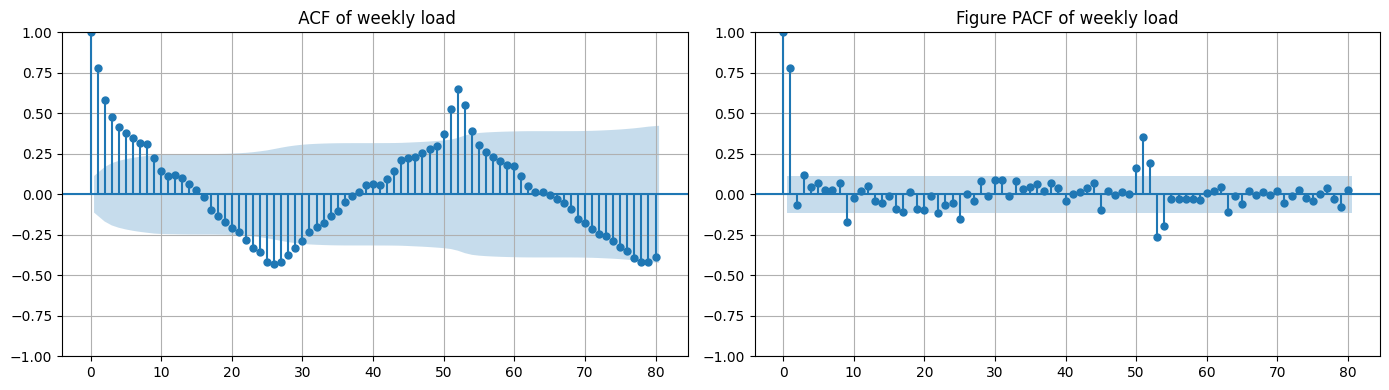

Stationarity note:
ADF, ACF, PACF and differencing results will be used to justify SARIMA differencing and seasonal period.


In [9]:
# ============================================================
# Cell 6: Stationarity analysis
# ============================================================
# This cell performs required stationarity checks:
# 1. Rolling mean and rolling standard deviation
# 2. ADF test on original weekly load
# 3. ADF test after first differencing
# 4. ADF test after seasonal differencing
# 5. ACF and PACF plots

def adf_test(series, name):
    """Run Augmented Dickey-Fuller test and return key results."""
    result = adfuller(series.dropna(), autolag="AIC")
    output = {
        "Series": name,
        "ADF Statistic": result[0],
        "p-value": result[1],
        "Lags Used": result[2],
        "Observations": result[3],
        "Conclusion": "Stationary" if result[1] < 0.05 else "Non-stationary"
    }
    return output

rolling_mean = weekly_load.rolling(window=12).mean()
rolling_std = weekly_load.rolling(window=12).std()

plt.figure(figsize=(12, 5))
plt.plot(weekly_load, label="Weekly load")
plt.plot(rolling_mean, label="12-week rolling mean")
plt.plot(rolling_std, label="12-week rolling standard deviation")
plt.title("Rolling mean and standard deviation of weekly load")
plt.xlabel("Date")
plt.ylabel("Load / rolling statistic")
plt.legend()
save_figure("rolling_mean_std_weekly_load.png")
plt.show()

first_diff = weekly_load.diff()
seasonal_diff = weekly_load.diff(52)

adf_results = pd.DataFrame([
    adf_test(weekly_load, "Original weekly load"),
    adf_test(first_diff, "First differenced weekly load"),
    adf_test(seasonal_diff, "Seasonally differenced weekly load")
])

print("ADF test results")
display(adf_results)

# Figure 4: ACF and PACF before differencing.
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(weekly_load.dropna(), lags=80, ax=axes[0])
axes[0].set_title(" ACF of weekly load")
plot_pacf(weekly_load.dropna(), lags=80, ax=axes[1], method="ywm")
axes[1].set_title("Figure PACF of weekly load")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "figure_4_acf_pacf_weekly_load.png"), dpi=300, bbox_inches="tight")
plt.show()

print("Stationarity note:")
print("ADF, ACF, PACF and differencing results will be used to justify SARIMA differencing and seasonal period.")

Train-test split
------------------------------------------------------------
Training period: 2015-01-04 00:00:00+00:00 to 2018-10-07 00:00:00+00:00 (197 weeks)
Test period: 2018-10-14 00:00:00+00:00 to 2020-10-04 00:00:00+00:00 (104 weeks)
Benchmark model metrics


,Model,RMSE,MAE,sMAPE,Improvement_vs_Seasonal_Naive_%
0,Mean,4397.299694,3788.833122,6.871234,-64.577204
1,Naive,4459.108546,3783.202934,6.861803,-66.890517
2,Seasonal Naive,2671.876531,2063.028369,3.784492,0.000000
3,Drift,5117.957264,4339.890674,7.848103,-91.549168


Saved figure: figures/figure_5_benchmark_forecasts.png


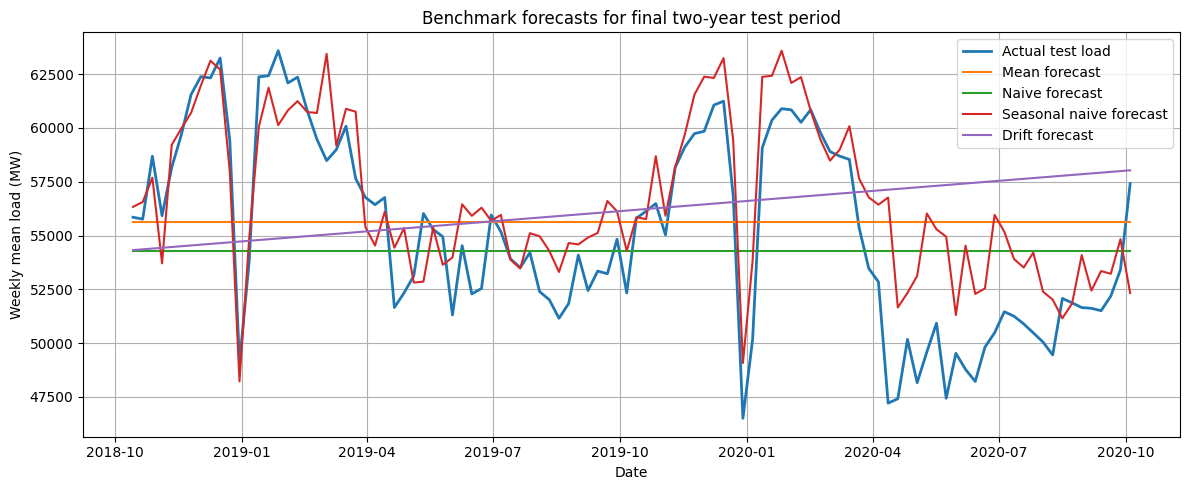

In [10]:
# ============================================================
# Cell 7: Train-test split and benchmark forecasts
# ============================================================
# Forecast horizon: final 104 weeks, approximately two years.
# Benchmark models required by the assignment:
# 1. Mean forecast
# 2. Naive forecast
# 3. Seasonal naive forecast
# 4. Drift forecast

train = train_weekly.copy()
test = test_weekly.copy()
h = len(test)

print("Train-test split")
print("-" * 60)
print(f"Training period: {train.index.min()} to {train.index.max()} ({len(train)} weeks)")
print(f"Test period: {test.index.min()} to {test.index.max()} ({len(test)} weeks)")

# Mean forecast: repeat the average training value.
mean_forecast = pd.Series(train.mean(), index=test.index)

# Naive forecast: repeat the final training value.
naive_forecast = pd.Series(train.iloc[-1], index=test.index)

# Seasonal naive forecast: copy value from 52 weeks earlier.
season_length = 52
seasonal_naive_values = []
history = weekly_load.copy()

for date in test.index:
    previous_season_date = date - pd.DateOffset(weeks=season_length)
    if previous_season_date in history.index:
        seasonal_naive_values.append(history.loc[previous_season_date])
    else:
        seasonal_naive_values.append(train.iloc[-season_length])

seasonal_naive_forecast = pd.Series(seasonal_naive_values, index=test.index)

# Drift forecast:
# y_T + h * ((y_T - y_1) / (T - 1))
T = len(train)
drift_slope = (train.iloc[-1] - train.iloc[0]) / (T - 1)
drift_forecast = pd.Series(
    [train.iloc[-1] + (i + 1) * drift_slope for i in range(h)],
    index=test.index
)

# Evaluate benchmarks.
benchmark_metrics = []
benchmark_metrics.append(evaluate_forecast("Mean", test, mean_forecast))
benchmark_metrics.append(evaluate_forecast("Naive", test, naive_forecast))
benchmark_metrics.append(evaluate_forecast("Seasonal Naive", test, seasonal_naive_forecast))
benchmark_metrics.append(evaluate_forecast("Drift", test, drift_forecast))

benchmark_table = pd.DataFrame(benchmark_metrics)
seasonal_naive_rmse = benchmark_table.loc[
    benchmark_table["Model"] == "Seasonal Naive", "RMSE"
].iloc[0]

# Recalculate improvement column using seasonal naive as baseline.
benchmark_table = pd.DataFrame([
    evaluate_forecast("Mean", test, mean_forecast, seasonal_naive_rmse),
    evaluate_forecast("Naive", test, naive_forecast, seasonal_naive_rmse),
    evaluate_forecast("Seasonal Naive", test, seasonal_naive_forecast, seasonal_naive_rmse),
    evaluate_forecast("Drift", test, drift_forecast, seasonal_naive_rmse)
])

metrics_results.extend(benchmark_table.to_dict("records"))

print("Benchmark model metrics")
display(benchmark_table)

# Figure 5: Benchmark forecasts.
plt.figure(figsize=(12, 5))
plt.plot(test.index, test.values, label="Actual test load", linewidth=2)
plt.plot(mean_forecast.index, mean_forecast.values, label="Mean forecast")
plt.plot(naive_forecast.index, naive_forecast.values, label="Naive forecast")
plt.plot(seasonal_naive_forecast.index, seasonal_naive_forecast.values, label="Seasonal naive forecast")
plt.plot(drift_forecast.index, drift_forecast.values, label="Drift forecast")
plt.title("Benchmark forecasts for final two-year test period")
plt.xlabel("Date")
plt.ylabel("Weekly mean load (MW)")
plt.legend()
save_figure("figure_5_benchmark_forecasts.png")
plt.show()

In [13]:
# ============================================================
# Cell 8: Faster SARIMA AIC parameter search
# ============================================================
# This cell follows the assignment requirement by looping through:
# p = 0 to 6
# d = 0 to 2
# q = 0 to 6
#
# To keep runtime practical, the seasonal component is fixed as (1,1,1,52),
# because the weekly data has annual seasonality and 52 weeks represent one year.

import warnings
from statsmodels.tools.sm_exceptions import ConvergenceWarning

warnings.simplefilter("ignore", ConvergenceWarning)
warnings.simplefilter("ignore", UserWarning)
warnings.simplefilter("ignore", RuntimeWarning)

p_values = range(0, 7)
d_values = range(0, 3)
q_values = range(0, 7)

seasonal_order_fixed = (1, 1, 1, 52)

sarima_results = []

total_models = len(list(p_values)) * len(list(d_values)) * len(list(q_values))
print(f"Total SARIMA combinations to try: {total_models}")
print("This follows the required p,d,q search from the assignment.")

counter = 0
successful_models = 0
failed_models = 0

for p, d, q in itertools.product(p_values, d_values, q_values):
    counter += 1
    order = (p, d, q)

    try:
        model = SARIMAX(
            train,
            order=order,
            seasonal_order=seasonal_order_fixed,
            enforce_stationarity=False,
            enforce_invertibility=False,
            simple_differencing=True
        )

        fitted = model.fit(
            disp=False,
            maxiter=20,
            method="lbfgs"
        )

        if np.isfinite(fitted.aic):
            sarima_results.append({
                "order": order,
                "seasonal_order": seasonal_order_fixed,
                "AIC": fitted.aic
            })
            successful_models += 1
        else:
            failed_models += 1

    except Exception:
        failed_models += 1
        continue

    if counter % 25 == 0:
        print(f"Checked {counter} / {total_models} | Successful: {successful_models} | Failed/skipped: {failed_models}")

sarima_aic_table = pd.DataFrame(sarima_results).sort_values("AIC").reset_index(drop=True)

print("\nSARIMA search completed")
print("-" * 60)
print(f"Total checked: {counter}")
print(f"Successful models: {successful_models}")
print(f"Failed/skipped models: {failed_models}")

print("\nTop 10 SARIMA models by AIC")
display(sarima_aic_table.head(10))

best_order = sarima_aic_table.loc[0, "order"]
best_seasonal_order = sarima_aic_table.loc[0, "seasonal_order"]
best_aic = sarima_aic_table.loc[0, "AIC"]

print("\nBest SARIMA model selected by AIC")
print(f"order = {best_order}")
print(f"seasonal_order = {best_seasonal_order}")
print(f"AIC = {best_aic:.2f}")

sarima_aic_table.to_csv(os.path.join(OUT_DIR, "sarima_aic_results.csv"), index=False)

Total SARIMA combinations to try: 147
This follows the required p,d,q search from the assignment.
Checked 25 / 147 | Successful: 25 | Failed/skipped: 0
Checked 50 / 147 | Successful: 50 | Failed/skipped: 0
Checked 75 / 147 | Successful: 75 | Failed/skipped: 0
Checked 100 / 147 | Successful: 100 | Failed/skipped: 0
Checked 125 / 147 | Successful: 125 | Failed/skipped: 0

SARIMA search completed
------------------------------------------------------------
Total checked: 147
Successful models: 147
Failed/skipped models: 0

Top 10 SARIMA models by AIC


,order,seasonal_order,AIC
0,"(2, 2, 6)","(1, 1, 1, 52)",1482.701298
1,"(3, 2, 6)","(1, 1, 1, 52)",1484.342846
2,"(4, 2, 6)","(1, 1, 1, 52)",1486.125658
3,"(1, 2, 6)","(1, 1, 1, 52)",1486.141324
4,"(5, 2, 6)","(1, 1, 1, 52)",1487.519498
5,"(0, 1, 6)","(1, 1, 1, 52)",1488.331884
6,"(1, 1, 6)","(1, 1, 1, 52)",1488.852243
7,"(0, 2, 6)","(1, 1, 1, 52)",1489.783598
8,"(2, 1, 6)","(1, 1, 1, 52)",1490.641153
9,"(3, 1, 6)","(1, 1, 1, 52)",1492.082789



Best SARIMA model selected by AIC
order = (2, 2, 6)
seasonal_order = (1, 1, 1, 52)
AIC = 1482.70


Best SARIMA model
------------------------------------------------------------
order = (2, 2, 6)
seasonal_order = (1, 1, 1, 52)
AIC = 1482.70

SARIMA evaluation


,Model,RMSE,MAE,sMAPE,Improvement_vs_Seasonal_Naive_%
0,SARIMA,55361.581892,55165.491743,196.662369,-1972.011234


Saved figure: figures/figure_6_sarima_forecast_ci.png


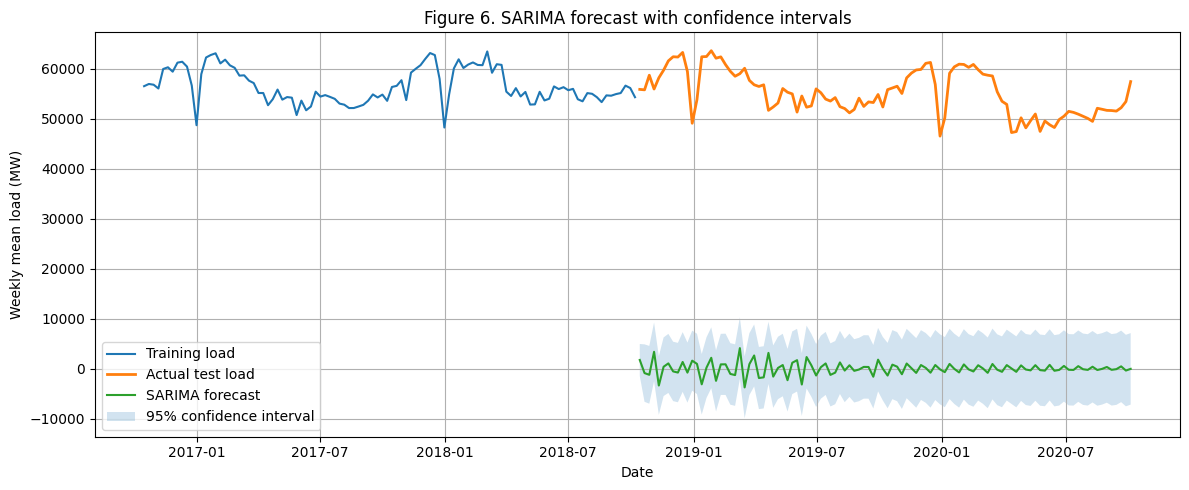

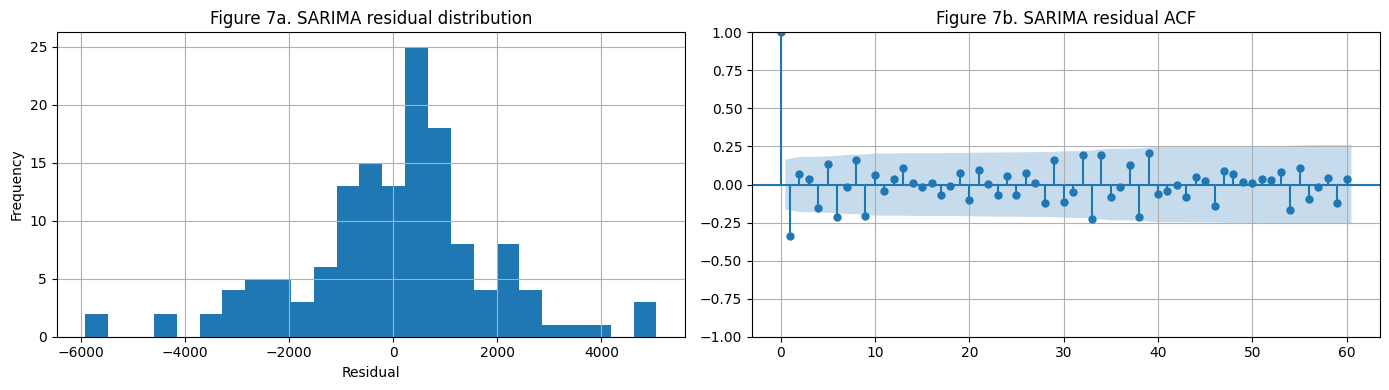

In [14]:
# The best AIC model is fitted again with a higher iteration limit before forecasting.
best_sarima_model = SARIMAX(
    train,
    order=best_order,
    seasonal_order=best_seasonal_order,
    enforce_stationarity=False,
    enforce_invertibility=False,
    simple_differencing=True
)

best_sarima_fit = best_sarima_model.fit(
    disp=False,
    maxiter=100,
    method="lbfgs"
)

# Forecast the same two-year test period used by the benchmark models.
sarima_forecast_result = best_sarima_fit.get_forecast(steps=h)
sarima_forecast = sarima_forecast_result.predicted_mean
sarima_ci = sarima_forecast_result.conf_int()

sarima_forecast.index = test.index
sarima_ci.index = test.index

sarima_metrics = evaluate_forecast("SARIMA", test, sarima_forecast, seasonal_naive_rmse)
metrics_results.append(sarima_metrics)

print("Best SARIMA model")
print("-" * 60)
print(f"order = {best_order}")
print(f"seasonal_order = {best_seasonal_order}")
print(f"AIC = {best_aic:.2f}")

print("\nSARIMA evaluation")
display(pd.DataFrame([sarima_metrics]))

plt.figure(figsize=(12, 5))
plt.plot(train.index[-104:], train.iloc[-104:], label="Training load")
plt.plot(test.index, test.values, label="Actual test load", linewidth=2)
plt.plot(sarima_forecast.index, sarima_forecast.values, label="SARIMA forecast")
plt.fill_between(
    test.index,
    sarima_ci.iloc[:, 0],
    sarima_ci.iloc[:, 1],
    alpha=0.2,
    label="95% confidence interval"
)
plt.title("Figure 6. SARIMA forecast with confidence intervals")
plt.xlabel("Date")
plt.ylabel("Weekly mean load (MW)")
plt.legend()
save_figure("figure_6_sarima_forecast_ci.png")
plt.show()

# Residuals are checked to see whether clear time-series structure remains after fitting.
residuals = best_sarima_fit.resid.dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(residuals, bins=25)
axes[0].set_title("Figure 7a. SARIMA residual distribution")
axes[0].set_xlabel("Residual")
axes[0].set_ylabel("Frequency")

plot_acf(residuals, lags=60, ax=axes[1])
axes[1].set_title("Figure 7b. SARIMA residual ACF")

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "figure_7_sarima_residual_diagnostics.png"), dpi=300, bbox_inches="tight")
plt.show()

SARIMAX evaluation


,Model,RMSE,MAE,sMAPE,Improvement_vs_Seasonal_Naive_%
0,SARIMAX_Temperature,55362.010528,55167.35081,196.818242,-1972.027277


Saved figure: figures/figure_8_sarimax_temperature_forecast.png


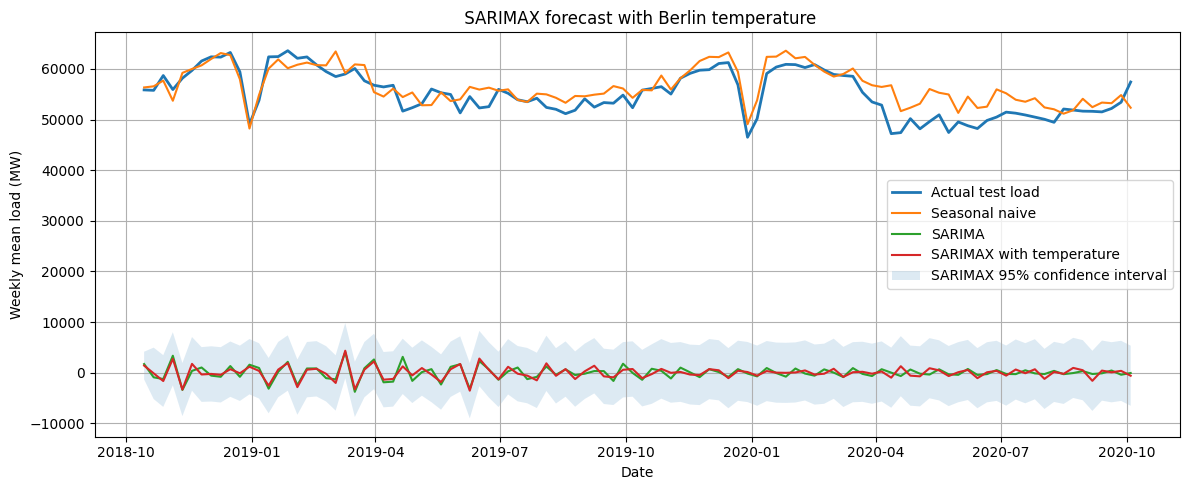

SARIMAX note:
Observed test-period temperature is used, so this is a conditional explanatory forecast.


In [17]:
TEMP_CACHE = os.path.join(OUT_DIR, "berlin_temperature_hourly.csv")

def get_berlin_temperature(start_date="2015-01-01", end_date="2020-09-30"):
    if os.path.exists(TEMP_CACHE):
        temp = pd.read_csv(TEMP_CACHE, parse_dates=["time"])
        return temp

    url = "https://archive-api.open-meteo.com/v1/archive"
    params = {
        "latitude": 52.52,
        "longitude": 13.41,
        "start_date": start_date,
        "end_date": end_date,
        "hourly": "temperature_2m",
        "timezone": "UTC"
    }

    response = requests.get(url, params=params, timeout=60)
    response.raise_for_status()
    data = response.json()

    temp = pd.DataFrame({
        "time": pd.to_datetime(data["hourly"]["time"], utc=True),
        "temperature_2m": data["hourly"]["temperature_2m"]
    })

    temp.to_csv(TEMP_CACHE, index=False)
    return temp

temp_hourly = get_berlin_temperature()
temp_hourly = temp_hourly.set_index("time").sort_index()

# Temperature is converted to weekly frequency so that it matches the weekly load model.
weekly_temp = temp_hourly["temperature_2m"].resample("W-SUN").mean()
weekly_temp = weekly_temp.reindex(weekly_load.index).interpolate(method="time")

sarimax_df = pd.DataFrame({
    "load": weekly_load,
    "temperature": weekly_temp
}).dropna()

train_exog = sarimax_df.loc[train.index, ["temperature"]]
test_exog = sarimax_df.loc[test.index, ["temperature"]]

sarimax_model = SARIMAX(
    train,
    exog=train_exog,
    order=best_order,
    seasonal_order=best_seasonal_order,
    enforce_stationarity=False,
    enforce_invertibility=False,
    simple_differencing=True
)

sarimax_fit = sarimax_model.fit(
    disp=False,
    maxiter=100,
    method="lbfgs"
)

# The test-period temperature is observed data, so this is treated as a conditional forecast.
sarimax_forecast_result = sarimax_fit.get_forecast(steps=h, exog=test_exog)
sarimax_forecast = sarimax_forecast_result.predicted_mean
sarimax_ci = sarimax_forecast_result.conf_int()

sarimax_forecast.index = test.index
sarimax_ci.index = test.index

sarimax_metrics = evaluate_forecast("SARIMAX_Temperature", test, sarimax_forecast, seasonal_naive_rmse)
metrics_results.append(sarimax_metrics)

print("SARIMAX evaluation")
display(pd.DataFrame([sarimax_metrics]))

plt.figure(figsize=(12, 5))
plt.plot(test.index, test.values, label="Actual test load", linewidth=2)
plt.plot(seasonal_naive_forecast.index, seasonal_naive_forecast.values, label="Seasonal naive")
plt.plot(sarima_forecast.index, sarima_forecast.values, label="SARIMA")
plt.plot(sarimax_forecast.index, sarimax_forecast.values, label="SARIMAX with temperature")
plt.fill_between(
    test.index,
    sarimax_ci.iloc[:, 0],
    sarimax_ci.iloc[:, 1],
    alpha=0.15,
    label="SARIMAX 95% confidence interval"
)
plt.title(" SARIMAX forecast with Berlin temperature")
plt.xlabel("Date")
plt.ylabel("Weekly mean load (MW)")
plt.legend()
save_figure("figure_8_sarimax_temperature_forecast.png")
plt.show()

print("SARIMAX note:")
print("Observed test-period temperature is used, so this is a conditional explanatory forecast.")

Gradient Boosting evaluation


,Model,RMSE,MAE,sMAPE,Improvement_vs_Seasonal_Naive_%
0,Gradient_Boosting,2802.873765,2068.031048,3.834511,-4.902818


Saved figure: figures/figure_9a_gradient_boosting_forecast.png


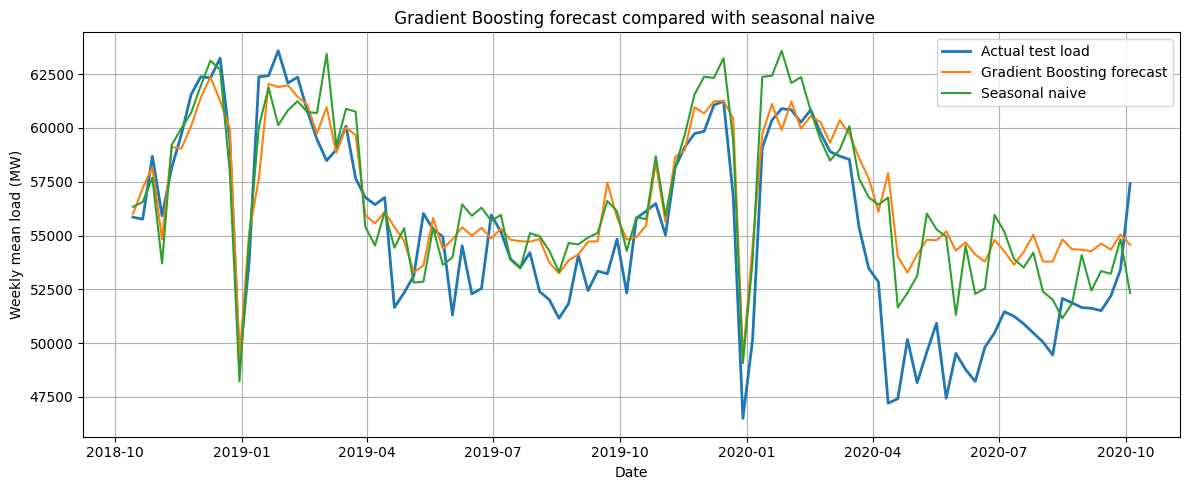

Saved figure: figures/figure_9b_gradient_boosting_feature_importance.png


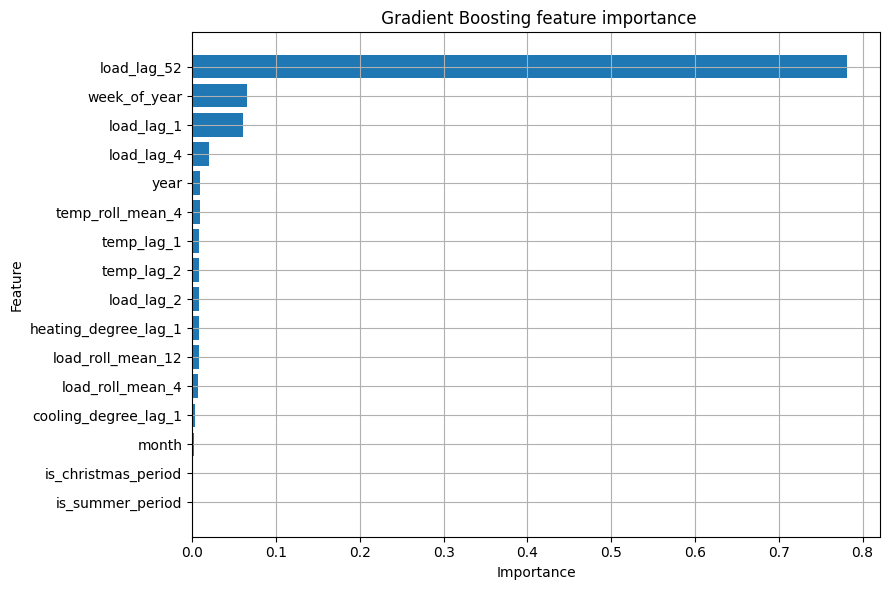

Leakage control:
Lag and rolling variables were shifted before modelling.


In [18]:
ml_df = pd.DataFrame({
    "load": weekly_load,
    "temperature": weekly_temp
})

# Calendar variables are known before the forecast period, so they can be used safely.
ml_df["week_of_year"] = ml_df.index.isocalendar().week.astype(int)
ml_df["month"] = ml_df.index.month
ml_df["year"] = ml_df.index.year

# Load lag features allow the model to learn from previous weeks.
ml_df["load_lag_1"] = ml_df["load"].shift(1)
ml_df["load_lag_2"] = ml_df["load"].shift(2)
ml_df["load_lag_4"] = ml_df["load"].shift(4)
ml_df["load_lag_52"] = ml_df["load"].shift(52)

# Rolling features are shifted first so that the current week is not included by accident.
ml_df["load_roll_mean_4"] = ml_df["load"].shift(1).rolling(4).mean()
ml_df["load_roll_mean_12"] = ml_df["load"].shift(1).rolling(12).mean()

# Temperature features are also lagged to avoid using information from the forecast week.
ml_df["temp_lag_1"] = ml_df["temperature"].shift(1)
ml_df["temp_lag_2"] = ml_df["temperature"].shift(2)
ml_df["temp_roll_mean_4"] = ml_df["temperature"].shift(1).rolling(4).mean()

ml_df["heating_degree_lag_1"] = np.maximum(0, 18 - ml_df["temp_lag_1"])
ml_df["cooling_degree_lag_1"] = np.maximum(0, ml_df["temp_lag_1"] - 18)

ml_df["is_christmas_period"] = ml_df["week_of_year"].isin([51, 52, 1]).astype(int)
ml_df["is_summer_period"] = ml_df["month"].isin([7, 8]).astype(int)

ml_df = ml_df.dropna()

feature_cols = [
    "week_of_year", "month", "year",
    "load_lag_1", "load_lag_2", "load_lag_4", "load_lag_52",
    "load_roll_mean_4", "load_roll_mean_12",
    "temp_lag_1", "temp_lag_2", "temp_roll_mean_4",
    "heating_degree_lag_1", "cooling_degree_lag_1",
    "is_christmas_period", "is_summer_period"
]

X = ml_df[feature_cols]
y = ml_df["load"]

X_train = X.loc[X.index.isin(train.index)]
y_train = y.loc[y.index.isin(train.index)]

X_test = X.loc[X.index.isin(test.index)]
y_test = y.loc[y.index.isin(test.index)]

gbr_model = GradientBoostingRegressor(
    n_estimators=300,
    learning_rate=0.03,
    max_depth=3,
    random_state=42
)

gbr_model.fit(X_train, y_train)

gbr_forecast = pd.Series(
    gbr_model.predict(X_test),
    index=X_test.index
)

gbr_actual = y_test.copy()

gbr_metrics = evaluate_forecast(
    "Gradient_Boosting",
    gbr_actual,
    gbr_forecast,
    seasonal_naive_rmse
)

metrics_results.append(gbr_metrics)

print("Gradient Boosting evaluation")
display(pd.DataFrame([gbr_metrics]))

plt.figure(figsize=(12, 5))
plt.plot(gbr_actual.index, gbr_actual.values, label="Actual test load", linewidth=2)
plt.plot(gbr_forecast.index, gbr_forecast.values, label="Gradient Boosting forecast")
plt.plot(
    seasonal_naive_forecast.loc[gbr_actual.index].index,
    seasonal_naive_forecast.loc[gbr_actual.index].values,
    label="Seasonal naive"
)
plt.title(" Gradient Boosting forecast compared with seasonal naive")
plt.xlabel("Date")
plt.ylabel("Weekly mean load (MW)")
plt.legend()
save_figure("figure_9a_gradient_boosting_forecast.png")
plt.show()

feature_importance = pd.Series(
    gbr_model.feature_importances_,
    index=feature_cols
).sort_values(ascending=True)

plt.figure(figsize=(9, 6))
plt.barh(feature_importance.index, feature_importance.values)
plt.title(" Gradient Boosting feature importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
save_figure("figure_9b_gradient_boosting_feature_importance.png")
plt.show()

print("Leakage control:")
print("Lag and rolling variables were shifted before modelling.")

Epoch 1/20
465/465 ━━━━━━━━━━━━━━━━━━━━ 31s 63ms/step - loss: 0.0243 - val_loss: 0.0043
Epoch 2/20
465/465 ━━━━━━━━━━━━━━━━━━━━ 31s 67ms/step - loss: 0.0068 - val_loss: 0.0021
Epoch 3/20
465/465 ━━━━━━━━━━━━━━━━━━━━ 31s 66ms/step - loss: 0.0048 - val_loss: 0.0018
Epoch 4/20
465/465 ━━━━━━━━━━━━━━━━━━━━ 30s 64ms/step - loss: 0.0038 - val_loss: 0.0010
Epoch 5/20
465/465 ━━━━━━━━━━━━━━━━━━━━ 30s 64ms/step - loss: 0.0031 - val_loss: 9.6487e-04
Epoch 6/20
465/465 ━━━━━━━━━━━━━━━━━━━━ 54s 92ms/step - loss: 0.0026 - val_loss: 8.4047e-04
Epoch 7/20
465/465 ━━━━━━━━━━━━━━━━━━━━ 30s 64ms/step - loss: 0.0022 - val_loss: 7.7288e-04
Epoch 8/20
465/465 ━━━━━━━━━━━━━━━━━━━━ 29s 63ms/step - loss: 0.0019 - val_loss: 7.3503e-04
Epoch 9/20
465/465 ━━━━━━━━━━━━━━━━━━━━ 31s 66ms/step - loss: 0.0017 - val_loss: 5.9860e-04
Epoch 10/20
465/465 ━━━━━━━━━━━━━━━━━━━━ 31s 67ms/step - loss: 0.0015 - val_loss: 6.3716e-04
Epoch 11/20
465/465 ━━━━━━━━━━━━━━━━━━━━ 29s 63ms/step - loss: 0.0013 - val_loss: 5.1604e-04
Ep

,Model,RMSE,MAE,sMAPE,Improvement_vs_Seasonal_Naive_%
0,LSTM_Hourly_168h,975.485165,274.355116,0.528992,63.490635


Saved figure: figures/figure_10a_lstm_training_loss.png


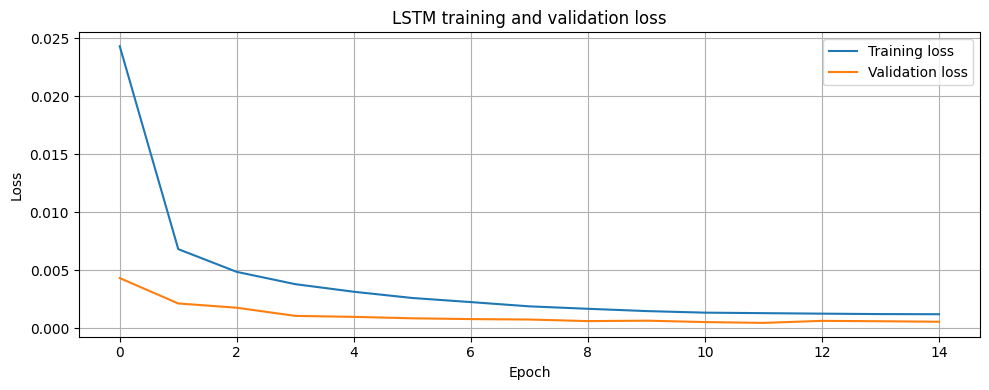

Saved figure: figures/figure_10b_lstm_weekly_forecast.png


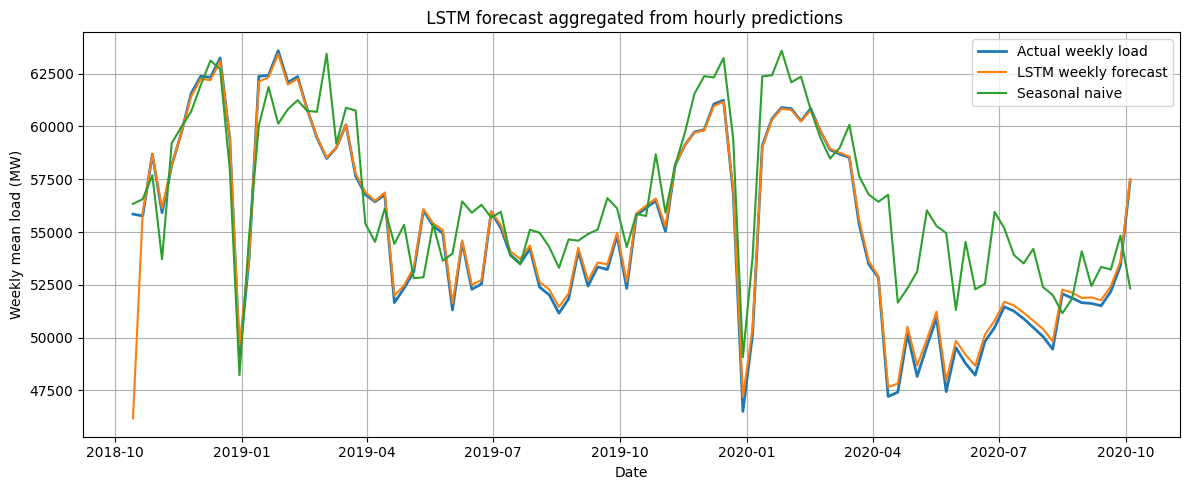

In [20]:
try:
    import tensorflow as tf
    from tensorflow.keras.models import Sequential
    from tensorflow.keras.layers import LSTM, Dense, Dropout
    from tensorflow.keras.callbacks import EarlyStopping

    tf.random.set_seed(42)
    np.random.seed(42)

    hourly_series = hourly_load.dropna().astype(float)
    lstm_test_start = test.index[0]

    train_hourly = hourly_series.loc[:lstm_test_start - pd.Timedelta(hours=1)]
    test_hourly = hourly_series.loc[lstm_test_start:]

    scaler = MinMaxScaler()
    train_scaled = scaler.fit_transform(train_hourly.values.reshape(-1, 1))
    test_scaled = scaler.transform(test_hourly.values.reshape(-1, 1))

    # A 168-hour sequence gives the model one full week of hourly history.
    sequence_length = 168

    def create_sequences(values, seq_len):
        X_seq, y_seq = [], []
        for i in range(seq_len, len(values)):
            X_seq.append(values[i-seq_len:i, 0])
            y_seq.append(values[i, 0])
        return np.array(X_seq), np.array(y_seq)

    X_train_lstm, y_train_lstm = create_sequences(train_scaled, sequence_length)

    # The last training week is attached to the test set so the first test prediction has enough history.
    combined_scaled = np.vstack([train_scaled[-sequence_length:], test_scaled])
    X_test_lstm, y_test_lstm = create_sequences(combined_scaled, sequence_length)

    X_train_lstm = X_train_lstm.reshape((X_train_lstm.shape[0], X_train_lstm.shape[1], 1))
    X_test_lstm = X_test_lstm.reshape((X_test_lstm.shape[0], X_test_lstm.shape[1], 1))

    lstm_model = Sequential([
        LSTM(32, input_shape=(sequence_length, 1)),
        Dropout(0.2),
        Dense(1)
    ])

    lstm_model.compile(
        optimizer="adam",
        loss="mse"
    )

    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )

    history = lstm_model.fit(
        X_train_lstm,
        y_train_lstm,
        epochs=20,
        batch_size=64,
        validation_split=0.1,
        callbacks=[early_stop],
        verbose=1
    )

    lstm_pred_scaled = lstm_model.predict(X_test_lstm, verbose=0)
    lstm_pred = scaler.inverse_transform(lstm_pred_scaled).flatten()
    lstm_actual = scaler.inverse_transform(y_test_lstm.reshape(-1, 1)).flatten()

    lstm_index = test_hourly.index[:len(lstm_pred)]

    lstm_hourly_forecast = pd.Series(lstm_pred, index=lstm_index)
    lstm_hourly_actual = pd.Series(lstm_actual, index=lstm_index)

    # Hourly predictions are aggregated to weekly means so they can be compared with the other models.
    lstm_weekly_forecast = lstm_hourly_forecast.resample("W-SUN").mean()
    lstm_weekly_actual = lstm_hourly_actual.resample("W-SUN").mean()

    common_lstm_index = lstm_weekly_forecast.index.intersection(test.index)

    lstm_weekly_forecast = lstm_weekly_forecast.loc[common_lstm_index]
    lstm_weekly_actual = weekly_load.loc[common_lstm_index]

    lstm_metrics = evaluate_forecast(
        "LSTM_Hourly_168h",
        lstm_weekly_actual,
        lstm_weekly_forecast,
        seasonal_naive_rmse
    )

    metrics_results.append(lstm_metrics)

    print("LSTM evaluation")
    display(pd.DataFrame([lstm_metrics]))

    plt.figure(figsize=(10, 4))
    plt.plot(history.history["loss"], label="Training loss")
    plt.plot(history.history["val_loss"], label="Validation loss")
    plt.title("LSTM training and validation loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    save_figure("figure_10a_lstm_training_loss.png")
    plt.show()

    plt.figure(figsize=(12, 5))
    plt.plot(lstm_weekly_actual.index, lstm_weekly_actual.values, label="Actual weekly load", linewidth=2)
    plt.plot(lstm_weekly_forecast.index, lstm_weekly_forecast.values, label="LSTM weekly forecast")
    plt.plot(
        seasonal_naive_forecast.loc[common_lstm_index].index,
        seasonal_naive_forecast.loc[common_lstm_index].values,
        label="Seasonal naive"
    )
    plt.title(" LSTM forecast aggregated from hourly predictions")
    plt.xlabel("Date")
    plt.ylabel("Weekly mean load (MW)")
    plt.legend()
    save_figure("figure_10b_lstm_weekly_forecast.png")
    plt.show()

except Exception as e:
    print("LSTM section did not run.")
    print(e)

Final model comparison


,Model,RMSE,MAE,sMAPE,Improvement_vs_Seasonal_Naive_%
0,LSTM_Hourly_168h,975.485165,274.355116,0.528992,63.490635
1,Seasonal Naive,2671.876531,2063.028369,3.784492,0.000000
2,Gradient_Boosting,2802.873765,2068.031048,3.834511,-4.902818
3,Mean,4397.299694,3788.833122,6.871234,-64.577204
4,Naive,4459.108546,3783.202934,6.861803,-66.890517
5,Drift,5117.957264,4339.890674,7.848103,-91.549168
6,SARIMA,55361.581892,55165.491743,196.662369,-1972.011234
7,SARIMAX_Temperature,55362.010528,55167.350810,196.818242,-1972.027277


Saved metrics table: outputs/final_model_metrics.csv
Saved figure: figures/figure_11_improvement_over_seasonal_naive.png


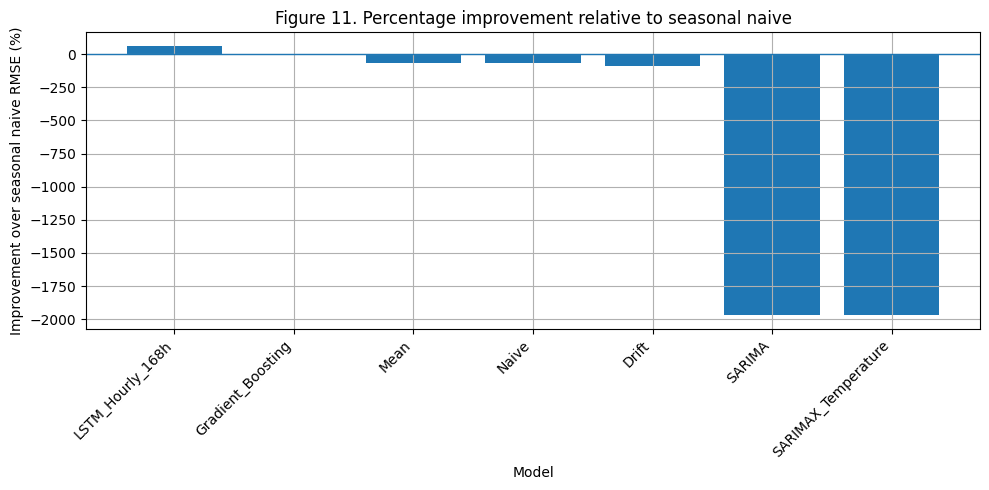

Best model by RMSE
------------------------------------------------------------
Model                              LSTM_Hourly_168h
RMSE                                     975.485165
MAE                                      274.355116
sMAPE                                      0.528992
Improvement_vs_Seasonal_Naive_%           63.490635
Name: 0, dtype: object


In [21]:
final_metrics = pd.DataFrame(metrics_results)

final_metrics = final_metrics.drop_duplicates(
    subset=["Model"],
    keep="last"
)

final_metrics = final_metrics.sort_values("RMSE").reset_index(drop=True)

print("Final model comparison")
display(final_metrics)

metrics_path = os.path.join(OUT_DIR, "final_model_metrics.csv")
final_metrics.to_csv(metrics_path, index=False)

print(f"Saved metrics table: {metrics_path}")

plot_df = final_metrics.copy()
plot_df = plot_df[plot_df["Model"] != "Seasonal Naive"]

plt.figure(figsize=(10, 5))
plt.bar(
    plot_df["Model"],
    plot_df["Improvement_vs_Seasonal_Naive_%"]
)
plt.axhline(0, linewidth=1)
plt.title("Figure 11. Percentage improvement relative to seasonal naive")
plt.xlabel("Model")
plt.ylabel("Improvement over seasonal naive RMSE (%)")
plt.xticks(rotation=45, ha="right")
save_figure("figure_11_improvement_over_seasonal_naive.png")
plt.show()

best_model = final_metrics.iloc[0]

print("Best model by RMSE")
print("-" * 60)
print(best_model)